In [15]:
%pip install xgboost imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

In [17]:
df = pd.read_csv("Travel.csv")

df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [18]:
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [19]:
print("\nTarget Distribution:\n", df['ProdTaken'].value_counts())


Target Distribution:
 ProdTaken
0    3968
1     920
Name: count, dtype: int64


In [20]:
# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include='object').columns
print(num_cols)
print(cat_cols)
# Fill missing numerical values
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining Missing Values:", df.isnull().sum().sum())

Index(['CustomerID', 'ProdTaken', 'Age', 'CityTier', 'DurationOfPitch',
       'NumberOfPersonVisiting', 'NumberOfFollowups', 'PreferredPropertyStar',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'NumberOfChildrenVisiting', 'MonthlyIncome'],
      dtype='object')
Index(['TypeofContact', 'Occupation', 'Gender', 'ProductPitched',
       'MaritalStatus', 'Designation'],
      dtype='object')
Remaining Missing Values: 0


In [21]:
x = df.drop(['ProdTaken', 'CustomerID'], axis=1)
y = df['ProdTaken']

print("Features Shape:", x.shape)
print("Target Shape:", y.shape)

Features Shape: (4888, 18)
Target Shape: (4888,)


In [22]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (3910, 18)
Testing Data: (978, 18)


In [28]:
#ENCODE
x_train = pd.get_dummies(x_train, drop_first=True, dtype=int)
x_test = pd.get_dummies(x_test, drop_first=True, dtype=int)

x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

In [29]:
print("Before SMOTE:\n", y_train.value_counts())

smote = SMOTE(random_state=42)
x_train_balanced, y_train_balanced = smote.fit_resample(
    x_train, y_train
)

print("\nAfter SMOTE:\n", pd.Series(y_train_balanced).value_counts())

Before SMOTE:
 ProdTaken
0    3174
1     736
Name: count, dtype: int64

After SMOTE:
 ProdTaken
0    3174
1    3174
Name: count, dtype: int64


In [30]:
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    eval_metric='logloss'
)

model.fit(x_train_balanced, y_train_balanced)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [31]:
y_pred = model.predict(x_test)

y_prob = model.predict_proba(x_test)[:, 1]

print("Actual Values:", list(y_test[:10]))
print("Predicted Values:", list(y_pred[:10]))

Actual Values: [1, 0, 1, 0, 0, 0, 0, 0, 0, 1]
Predicted Values: [np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]


In [32]:
auc = roc_auc_score(y_test, y_prob)
f1 = f1_score(y_test, y_pred)

print("AUC-ROC Score:", round(auc, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

AUC-ROC Score: 0.821
F1 Score: 0.5231

Classification Report:

              precision    recall  f1-score   support

           0       0.88      0.93      0.90       794
           1       0.60      0.46      0.52       184

    accuracy                           0.84       978
   macro avg       0.74      0.70      0.71       978
weighted avg       0.83      0.84      0.83       978



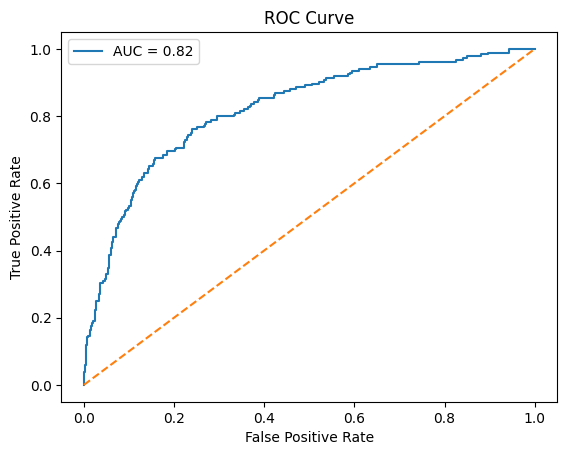

In [42]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label='AUC = %.2f' % auc)
plt.plot([0, 1], [0, 1], '--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

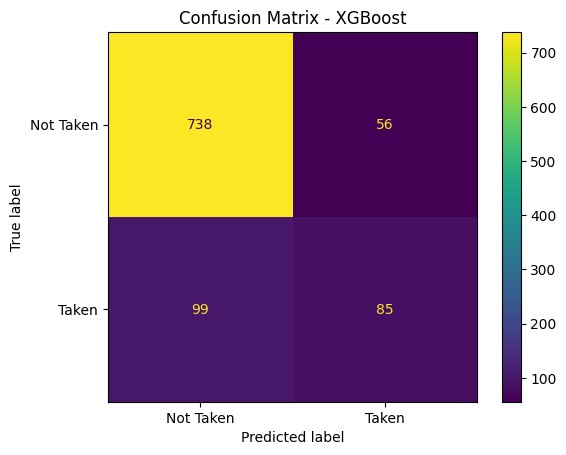

In [34]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Taken', 'Taken']
)

disp.plot()
plt.title('Confusion Matrix - XGBoost')
plt.show()